[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QNN_RotationNoiseCertified_Huang2023.ipynb)

# Certified robustness of a quantum classifier through random-rotation noise: Huang et al. (2023) step by step

**Paper.** Jhih-Cing Huang, Yu-Lin Tsai, Chao-Han Huck Yang, Cheng-Fang Su, Chia-Mu Yu, Pin-Yu Chen and Sy-Yen Kuo,
*Certified Robustness of Quantum Classifiers against Adversarial Examples through Quantum Noise*,
ICASSP 2023, DOI [10.1109/ICASSP49357.2023.10095030](https://doi.org/10.1109/ICASSP49357.2023.10095030),
arXiv [2211.00887](https://arxiv.org/abs/2211.00887).

**What this notebook does.** It rebuilds, on a classical computer, the whole chain of the paper: a 3-qubit variational
quantum classifier, the random Bloch-sphere rotation noise of "Algorithm 1" (a quantum analogue of randomised smoothing),
the accuracy-versus-noise-and-sample-size experiments (the paper's Figures 2 and 3), the statements that can be tested
numerically (Lemma 1, Proposition 2, Theorem 6, the differential-privacy based certified radius) and a real adversarial
attack (iterative FGSM and a stronger projected-gradient attack) to see whether the certificate really holds. A classical
randomised-smoothing classifier (Cohen et al.) trained on exactly the same inputs is the baseline.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` (default in the config cell) runs a small
demonstration in a few minutes; set it to `False` for the full budgets (10 seeds, 50 attack iterations as in the Du et al.
protocol the paper follows). No GPU, no account, no download: the data are the Iris flowers bundled with scikit-learn.

**What you get at the end.** Training curves, the drawn quantum circuits (with and without noise), an *exact* density-matrix
computation of the noisy classifier that is asserted equal to PennyLane's `default.mixed` simulator and to a Monte-Carlo
average of random rotations, accuracy-vs-sample-size curves, certified-radius curves, attack curves, a side-by-side table of
the paper's claims and what was measured here, and a critical reading.

## The paper in one page

* **Problem.** Quantum classifiers (parameterised circuits) are fooled by small adversarial perturbations of the input state.
* **Idea.** Classical *randomised smoothing* classifies `x + Gaussian noise` many times and takes the majority label. The
  quantum analogue: before the classifier, rotate every input qubit by a random angle `theta_i` (a random `RX(theta_i)` gate,
  the paper calls them "Pauli-X rotations"), with `0 < h1 < tan(theta_i) < h2`, run the circuit `N` times and use the
  average score `y~_k(sigma)`.
* **Claims (all theoretical, then checked on a small simulation).**
  1. *Lemma 1.* If the noiseless circuit gives the winning class probability `y_C(sigma) > (1+h)^n / 2`, the noisy circuit
     gives the same label (accuracy is not hurt).
  2. *Proposition 2.* With finite sampling the label is still `C` with probability at least `beta` if
     `N ~ ln(2/(1-beta)) / (8 (xi - (1+h)^n + 1)^2)` (the garbled "18" in the PDF text is 1/8).
  3. *Lemma 3.* The noisy classifier is `epsilon`-quantum-differentially-private with `epsilon = ln(1 + tau_D / t_n)`
     (`t_n` is the lower bound of the noise magnitude, see the table below).
  4. *Theorem 4 / 5 / 6.* If `B = y~_0(sigma)/y~_1(sigma) > exp(2 epsilon)` then every adversarial state `rho` with trace
     distance `tau(sigma, rho) <= tau_D` gets the same label, i.e. the certified radius is `tau_D < (sqrt(B) - 1) t_n`.
* **Experiment.** Input dimension 3, encoded into a three-qubit state (following Du et al., 2021); the lower noise bound
  is set to `t = 0` and the three angles are drawn from `U(0, h)`; Figure 2 shows test accuracy of the noiseless and the
  noisy classifier against the sample size; Figure 3 repeats this for `h = 2*pi/2^4`, `2*pi/2^8`, `2*pi/2^16` ("test noise
  4 / 8 / 16"). The curves themselves are images in the PDF and no numeric accuracy is quoted in the text, so the checks
  below are **qualitative**: "the difference is not obvious" and "the gap shrinks with a larger sample size".
* **Data.** Not named in the Huang paper. It states only that it follows Du et al., whose numerical section uses the Iris
  data, classes Setosa and Versicolour, with the fourth feature set to zero, `l2`-normalisation and amplitude encoding
  (60 training, 40 test examples). This notebook follows that description.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | not named (dimension 3, "following Du et al.") | Iris, Setosa vs Versicolour, first three features, `l2`-normalised (Du et al.'s setup), 60 train / 40 test, stratified random split per seed |
| Encoding | amplitude encoding, "three-qubit state" | the 3 features are padded with zeros to 8 amplitudes and loaded with `StatePrep` on 3 qubits (`# CHOICE`; Du et al. use 2 qubits, Huang says three) |
| Classifier | "model agnostic", no circuit given | `StronglyEntanglingLayers`, 3 layers, 27 parameters, class 0 = probability of qubit 0 being `|0>` (`# CHOICE`) |
| Training | parameter-shift gradients | Adam, squared loss, back-propagation through the simulator (the same gradient; one cell checks it against the parameter-shift rule) |
| Noise | `RX(theta_i)` before each input qubit, `theta_i ~ U(0, h)`, `t = 0` | identical; `h` in `{2pi/2^4, 2pi/2^8, 2pi/2^16}` plus extra levels up to `pi` |
| Meaning of "sample size" (Fig. 2/3 x-axis) | not defined | studied **both** ways: number `N` of noisy circuit executions per test point, and number of training examples |
| `t_n` in Lemma 3 / Theorem 6 | called "lower bound of noise magnitude"; set to 0 in the experiments | taken as the smallest eigenvalue of the noisy measurement operators, i.e. the largest `t_n` for which `y~_k(rho) >= t_n` holds for **every** state (`# CHOICE`, derivation in section 8) |
| Trace distance | written `Tr(\|\|sigma - rho\|\|)^2` in the PDF | standard `1/2 \|\|sigma - rho\|\|_1` |
| Attack | none in the text | I-FGSM (sign step, squared loss, `l2` budget, 50 iterations; the protocol of Du et al.) and a stronger tangent PGD with a margin loss, both on the unit sphere |
| Classical baseline | none | Gaussian randomised smoothing (Cohen et al.) of an MLP on the identical 3-d inputs, SVC(rbf) and RandomForest |

In [1]:
# Installs (pinned to the versions this notebook was executed with). Skipped when already importable.
import sys, subprocess, importlib
IN_COLAB = "google.colab" in sys.modules
try:
    import pennylane
    _have = pennylane.version() == "0.45.1"
except Exception:
    _have = False
if IN_COLAB and not _have:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1"])
    print("Installed pennylane==0.45.1 (if imports fail below, restart the session once and run again).")

In [2]:
# ---------------- configuration: every tunable constant ----------------
SEED = 42
FAST_MODE = False                 # True: a few minutes demo; False: full budgets (documented below)
N_QUBITS, N_LAYERS = 3, 3          # CHOICE: 3 qubits (paper), 3 StronglyEntanglingLayers (27 parameters)
N_TRAIN, N_TEST = 60, 40           # as in Du et al., whom the paper follows
LR = 0.1                           # CHOICE: Adam learning rate
EPOCHS = 40 if FAST_MODE else 60   # CHOICE
N_SEEDS = 3 if FAST_MODE else 10   # independent splits / initialisations (mean +- std)
N_SEEDS_SWEEP = 2 if FAST_MODE else 5     # training-size sweep
H_TRAIN = 2*3.141592653589793/2**4        # noise level used when the classifier is trained with noise
H_LEVELS = {"4": 2*3.141592653589793/2**4, "8": 2*3.141592653589793/2**8, "16": 2*3.141592653589793/2**16}  # paper's test noises
H_EXTRA = [3.141592653589793/4, 3.141592653589793/2, 3.141592653589793]      # extra, much larger noise levels
N_GRID = [1, 2, 4, 8, 16, 32, 64, 128] if FAST_MODE else [1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]
TRAIN_SIZES = [6, 12, 24, 36, 60]
MC_REPS = 40 if FAST_MODE else 200        # repetitions of the finite-sample experiments
ATTACK_STEPS = 20 if FAST_MODE else 50    # paper/Du et al.: 50 iterations
N_L = 8 if FAST_MODE else 15              # number of attack budgets in (0, 0.7]
CERT_L = [0, 0.01, 0.02, 0.03, 0.05, 0.075, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.7]   # radii at which certified accuracy is reported
RS_N = 300 if FAST_MODE else 1000         # Monte-Carlo noise draws of randomised smoothing
RS_SIGMAS = [0.05, 0.1, 0.2]
KRAUS_NODES = 24                          # Gauss-Legendre nodes that represent U(0,h) exactly in the channel
DATA_DIR = "iris_cache"                   # Iris ships inside scikit-learn, nothing is downloaded
IBM_TOKEN = ""                            # unused (no hardware cell); kept for the template
# Full run budget: 10 seeds x (2 models x 60 epochs), 50-step attacks on 15 budgets, N up to 1024, RS_N = 1000 (see the printed run time at the end).

In [3]:
import os, time, math, warnings, platform
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import pennylane as qml
from pennylane import numpy as pnp
import sklearn, scipy
from scipy.stats import norm, beta
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
warnings.filterwarnings("ignore")
np.random.seed(SEED)
rng_global = np.random.default_rng(SEED)
L_GRID = np.linspace(0, 0.7, N_L)
T0 = time.time()
RES = {}                                   # results collected for the final comparison
print("python", platform.python_version(), "| numpy", np.__version__, "| pennylane", qml.version(),
      "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| seeds:", N_SEEDS, "| epochs:", EPOCHS, "| attack steps:", ATTACK_STEPS)

python 3.12.10 | numpy 2.5.4 | pennylane 0.45.1 | scipy 1.18.1 | scikit-learn 1.9.1
FAST_MODE = False | seeds: 10 | epochs: 60 | attack steps: 50


## Dataset Exploration and Visualisation

The data are the classic Iris measurements (Fisher 1936, UCI), loaded from scikit-learn's bundled copy, so they are real
observations and nothing is generated. The paper's (Du et al.'s) experiment keeps two of the three species. We print the
complete original table first, then show the class distribution, and finally a labelled 2-D projection of the real flowers.

Original Iris data: (150, 4) | original label values: {np.str_('setosa'): np.int64(50), np.str_('versicolor'): np.int64(50), np.str_('virginica'): np.int64(50)}
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count             150.00            150.00             150.00   
mean                5.84              3.06               3.76   
std                 0.83              0.44               1.77   
min                 4.30              2.00               1.00   
25%                 5.10              2.80               1.60   
50%                 5.80              3.00               4.35   
75%                 6.40              3.30               5.10   
max                 7.90              4.40               6.90   

       petal width (cm)  
count            150.00  
mean               1.20  
std                0.76  
min                0.10  
25%                0.30  

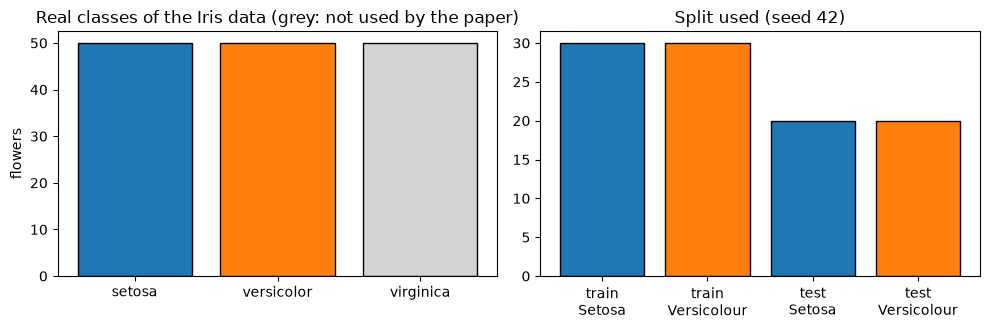

In [4]:
iris = load_iris()
X_all, y_all = iris.data, iris.target
species = list(iris.target_names)
print("Original Iris data:", X_all.shape, "| original label values:", dict(zip(species, np.bincount(y_all))))
print("Feature names:", iris.feature_names)
print(pd.DataFrame(X_all, columns=iris.feature_names).assign(species=[species[i] for i in y_all]).describe().round(2).iloc[:, :4])

def make_split(seed, n_train=N_TRAIN):
    # Setosa (0) vs Versicolour (1); the 4th feature is dropped (= set to 0 in Du et al.), then l2 normalisation (per example)
    m = y_all < 2
    X3 = X_all[m][:, :3]
    y = y_all[m]
    Xn = X3 / np.linalg.norm(X3, axis=1, keepdims=True)
    Xtr, Xte, ytr, yte = train_test_split(Xn, y, test_size=N_TEST, stratify=y, random_state=seed)
    if n_train < len(Xtr):
        Xtr, _, ytr, _ = train_test_split(Xtr, ytr, train_size=n_train, stratify=ytr, random_state=seed)
    return Xtr, ytr, Xte, yte

def amp(X):                       # amplitude vector on 3 qubits: 3 features padded with zeros (CHOICE)
    A = np.zeros((len(X), 8)); A[:, :3] = X
    return A

Xtr0, ytr0, Xte0, yte0 = make_split(SEED)
print(f"Used for the model: Setosa vs Versicolour, input dimension 3 -> train {Xtr0.shape}, test {Xte0.shape}")
print("train class counts:", dict(zip(species[:2], np.bincount(ytr0))), "| test:", dict(zip(species[:2], np.bincount(yte0))))
print("every input has unit l2 norm:", np.allclose(np.linalg.norm(Xtr0, axis=1), 1))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
cnt = np.bincount(y_all)
ax[0].bar(species, cnt, color=["tab:blue", "tab:orange", "lightgrey"], edgecolor="k")
ax[0].set_title("Real classes of the Iris data (grey: not used by the paper)"); ax[0].set_ylabel("flowers")
ax[1].bar(["train\nSetosa", "train\nVersicolour", "test\nSetosa", "test\nVersicolour"],
          list(np.bincount(ytr0)) + list(np.bincount(yte0)), color=["tab:blue", "tab:orange"] * 2, edgecolor="k")
ax[1].set_title(f"Split used (seed {SEED})")
plt.tight_layout(); plt.show()

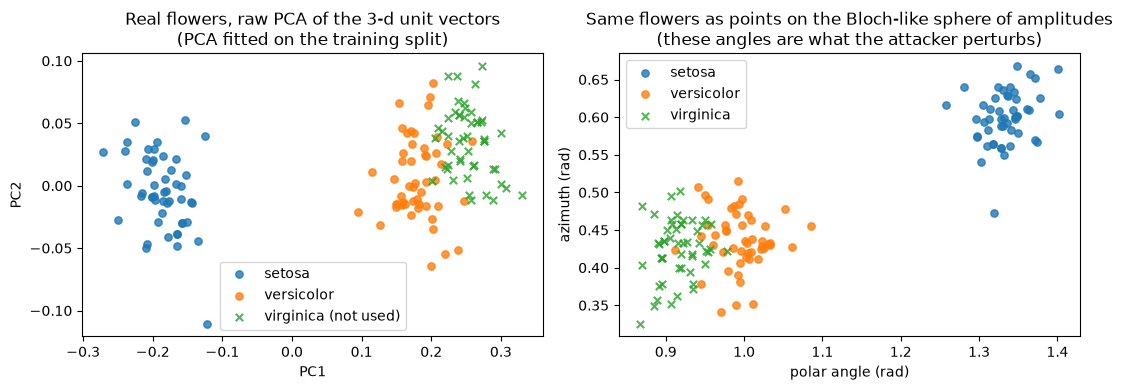

In [5]:
# 2-D scatter of real flowers coloured by ground-truth species. PCA is fitted on the training split only.
Xn_all = X_all[:, :3] / np.linalg.norm(X_all[:, :3], axis=1, keepdims=True)
pca = PCA(n_components=2, random_state=SEED).fit(Xtr0)
cols = {0: "tab:blue", 1: "tab:orange", 2: "tab:green"}
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for c in range(3):
    mk = "o" if c < 2 else "x"
    Z = pca.transform(Xn_all[y_all == c])
    ax[0].scatter(Z[:, 0], Z[:, 1], c=cols[c], marker=mk, s=28, alpha=.8, label=species[c] + ("" if c < 2 else " (not used)"))
ax[0].set_title("Real flowers, raw PCA of the 3-d unit vectors\n(PCA fitted on the training split)")
ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend()
# the quantum state only depends on the direction of the unit vector: polar and azimuth angles of the amplitude vector
def sph(X):
    return np.arccos(np.clip(X[:, 2], -1, 1)), np.arctan2(X[:, 1], X[:, 0])
for c in range(3):
    th, ph = sph(Xn_all[y_all == c])
    ax[1].scatter(th, ph, c=cols[c], marker="o" if c < 2 else "x", s=28, alpha=.8, label=species[c])
ax[1].set_title("Same flowers as points on the Bloch-like sphere of amplitudes\n(these angles are what the attacker perturbs)")
ax[1].set_xlabel("polar angle (rad)"); ax[1].set_ylabel("azimuth (rad)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 1. The quantum model: circuit, exact noisy computation and simulator checks

The paper's Algorithm 1 puts one rotation `RX(theta_i)` on every input qubit (after the input state is prepared and before
the classifier) and averages the classifier's output over the random angles. We write the circuit three times with
the same gates:

* `qnn` - noiseless classifier (`StatePrep` + `StronglyEntanglingLayers` + measurement of qubit 0);
* `qnn_rot` - the *executed noisy circuit*: one random draw of the three angles (Monte-Carlo path, `default.qubit`);
* `qnn_mixed` - the same noise **averaged exactly** as a quantum channel on `default.mixed`. Because
  `E_theta[RX(theta) rho RX(theta)^dagger]` is a mixture of unitaries with a smooth weight, Gauss-Legendre quadrature with 24
  nodes represents `U(0,h)` to machine precision, so the channel's Kraus operators are `sqrt(w_j) RX(theta_j)`.

The class probabilities are `y_0 = P(qubit 0 = |0>)` and `y_1 = 1 - y_0`; the predicted label is the larger one.

In [6]:
dev = qml.device("default.qubit", wires=N_QUBITS)
dev_m = qml.device("default.mixed", wires=N_QUBITS)
W_SHAPE = (N_LAYERS, N_QUBITS, 3)

def variational(w):
    qml.StronglyEntanglingLayers(w, wires=range(N_QUBITS))

@qml.qnode(dev, interface="autograd", diff_method="backprop")
def qnn(w, a):
    qml.StatePrep(a, wires=range(N_QUBITS))
    variational(w)
    return qml.expval(qml.Projector([0], wires=[0]))             # y_0 = P(qubit0 = 0)

@qml.qnode(dev, interface="autograd", diff_method="backprop")
def qnn_rot(w, a, th):                                           # one noisy execution: RX(theta_i) on every input qubit
    qml.StatePrep(a, wires=range(N_QUBITS))
    for q in range(N_QUBITS):
        qml.RX(th[..., q], wires=q)
    variational(w)
    return qml.expval(qml.Projector([0], wires=[0]))

@qml.qnode(dev_m)
def qnn_mixed(w, a, kraus, p_depol):                             # averaged noise as a channel (+ optional output depolarisation)
    qml.StatePrep(a, wires=range(N_QUBITS))
    for q in range(N_QUBITS):
        qml.QubitChannel(kraus, wires=q)
    variational(w)
    if p_depol > 0:
        qml.DepolarizingChannel(3 * p_depol / 4, wires=0)       # rho -> (1-p) rho + p I/2  (Du et al.'s channel)
    return qml.expval(qml.Projector([0], wires=[0]))

I2 = np.eye(2)
def rx_np(t):
    return np.array([[np.cos(t / 2), -1j * np.sin(t / 2)], [-1j * np.sin(t / 2), np.cos(t / 2)]])
def kron3(a, b, c):
    return np.kron(np.kron(a, b), c)
P0 = kron3(np.diag([1., 0.]), I2, I2)

def gl_nodes(h, Q=KRAUS_NODES):
    x, wt = np.polynomial.legendre.leggauss(Q)
    return h * (x + 1) / 2, wt / 2                               # nodes in [0,h], weights summing to 1 (uniform density)

def kraus_list(h):
    th, wt = gl_nodes(h)
    return [np.sqrt(wj) * rx_np(t) for wj, t in zip(wt, th)]

def unitary(w):
    return qml.matrix(qml.StronglyEntanglingLayers(np.asarray(w), wires=range(N_QUBITS)), wire_order=list(range(N_QUBITS)))

_POVM = {}
def effective_povm(w, h):
    # Heisenberg picture: Pi~_0 = E^dagger(U^dagger P0 U) with E the average over the three random rotations.
    key = (np.asarray(w).tobytes(), float(h))
    if key in _POVM:
        return _POVM[key]
    U = unitary(w)
    O = U.conj().T @ P0 @ U
    if h > 0:
        th, wt = gl_nodes(h)
        for q in range(N_QUBITS):
            acc = np.zeros_like(O)
            for t, wj in zip(th, wt):
                ops = [I2, I2, I2]; ops[q] = rx_np(t)
                R = kron3(*ops)
                acc = acc + wj * (R.conj().T @ O @ R)
            O = acc
    O = 0.5 * (O + O.conj().T)
    _POVM[key] = (O, np.real(O))
    return _POVM[key]

def y0_of(M, A):                                                  # exact noisy y~_0 for rows of A (real amplitude vectors)
    return np.einsum("ni,ij,nj->n", A, M, A)

In [7]:
# ---- equivalence checks: exact density-matrix result == simulators ----
rng = np.random.default_rng(SEED)
w_chk = pnp.array(rng.uniform(-np.pi, np.pi, W_SHAPE), requires_grad=True)
A_chk = amp(Xte0[:6])
h_chk = H_LEVELS["4"]
O_chk, M_chk = effective_povm(w_chk, h_chk)
exact = y0_of(M_chk, A_chk)

# (a) noiseless circuit == U^dagger P0 U
assert np.allclose(np.array(qnn(w_chk, A_chk)), y0_of(effective_povm(w_chk, 0)[1], A_chk), atol=1e-10)
# (b) default.mixed with the 24-node Kraus channel on every qubit
mixed = np.array([qnn_mixed(w_chk, a, kraus_list(h_chk), 0.0) for a in A_chk])
assert np.allclose(mixed, exact, atol=1e-8), (mixed, exact)
# (c) depolarising output channel: y~ = p/2 + (1-p) y
y_clean = np.array(qnn(w_chk, A_chk))
mixed_p = np.array([qnn_mixed(w_chk, a, kraus_list(1e-9), 0.5) for a in A_chk])
assert np.allclose(mixed_p, 0.25 + 0.5 * y_clean, atol=1e-6)
# (d) Monte-Carlo: random angles theta ~ U(0,h) executed on default.qubit (batched), N draws per input
n_mc = 40000
th_mc = pnp.array(rng.uniform(0, h_chk, (n_mc, 3)), requires_grad=False)
mc = np.array([np.mean(np.array(qnn_rot(w_chk, np.tile(a, (n_mc, 1)), th_mc))) for a in A_chk])
sd = 1 / np.sqrt(n_mc) / 2
print("exact           :", exact.round(5))
print("default.mixed   :", mixed.round(5))
print("Monte-Carlo (4e4):", mc.round(5), "| max |MC - exact| =", np.abs(mc - exact).max().round(5), "(sampling sd about", sd.round(5), ")")
assert np.abs(mc - exact).max() < 5 * sd
# (e) parameter-shift gradient equals back-propagation (the paper trains with the parameter-shift rule)
dev_ps = qml.device("default.qubit", wires=N_QUBITS)
@qml.qnode(dev_ps, diff_method="parameter-shift")
def qnn_ps(w, a):
    qml.StatePrep(a, wires=range(N_QUBITS)); variational(w)
    return qml.expval(qml.Projector([0], wires=[0]))
g_ps = qml.grad(lambda w: qnn_ps(w, A_chk[0]))(w_chk)
g_bp = qml.grad(lambda w: qnn(w, A_chk[0]))(w_chk)
print("parameter-shift vs back-prop gradient, max abs difference:", float(np.abs(g_ps - g_bp).max()))
assert np.allclose(g_ps, g_bp, atol=1e-8)
print("All simulator equivalence assertions passed.")

exact           : [0.31031 0.30968 0.26244 0.30026 0.31757 0.33771]
default.mixed   : [0.31031 0.30968 0.26244 0.30026 0.31757 0.33771]
Monte-Carlo (4e4): [0.31045 0.30982 0.26255 0.30041 0.31771 0.33786] | max |MC - exact| = 0.00014 (sampling sd about 0.0025 )


parameter-shift vs back-prop gradient, max abs difference: 3.608224830031759e-16
All simulator equivalence assertions passed.


## Quantum Circuit Architecture

The three drawings below are produced by `qml.draw_mpl` from the QNodes that are really executed in this notebook: the noiseless
classifier, the noisy circuit of Algorithm 1 (one random draw of the three rotation angles) and the exact-average version on
`default.mixed` (the `QubitChannel` boxes are the averaged random rotations). The paper gives no circuit details, so the following
are assumptions (`# CHOICE`): amplitude encoding is realised by `StatePrep` of the zero-padded 3-vector on 3 qubits, the trainable
block is 3 layers of `StronglyEntanglingLayers` (a general `Rot` rotation on every qubit followed by a ring of CNOTs), the label
is read from qubit 0 in the computational basis.

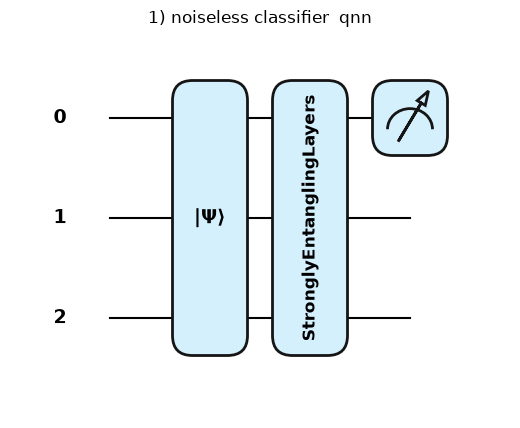

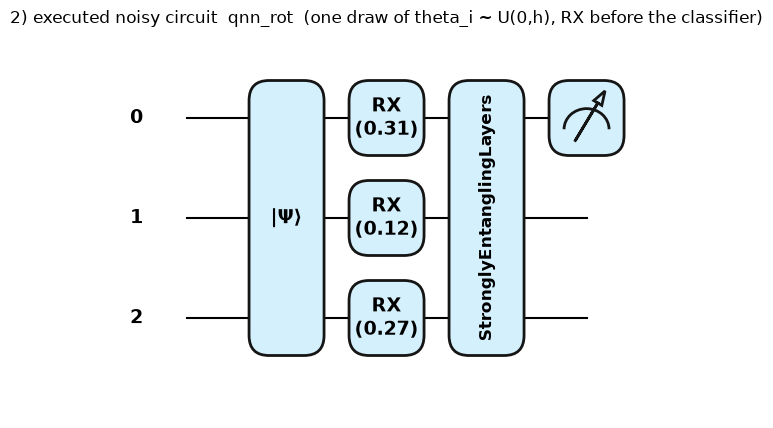

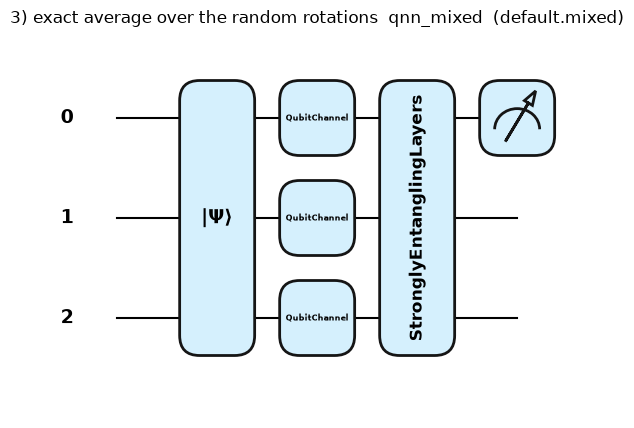

qubits = 3 | trainable parameters = 27 (noise angles are random, not trainable)
qnn (noiseless)              circuit depth after decomposition to the device gate set = 13
qnn_rot (noisy execution)    circuit depth after decomposition to the device gate set = 14


In [8]:
w_draw = pnp.array(np.random.default_rng(1).uniform(-np.pi, np.pi, W_SHAPE), requires_grad=False)
a_draw = amp(Xte0[:1])[0]
th_draw = pnp.array([0.31, 0.12, 0.27], requires_grad=False)
fig, _ = qml.draw_mpl(qnn, decimals=2, style="pennylane")(w_draw, a_draw)
fig.suptitle("1) noiseless classifier  qnn", y=1.02); plt.show()
fig, _ = qml.draw_mpl(qnn_rot, decimals=2, style="pennylane")(w_draw, a_draw, th_draw)
fig.suptitle("2) executed noisy circuit  qnn_rot  (one draw of theta_i ~ U(0,h), RX before the classifier)", y=1.02); plt.show()
fig, _ = qml.draw_mpl(qnn_mixed, decimals=2, style="pennylane")(w_draw, a_draw, kraus_list(H_LEVELS["4"]), 0.0)
fig.suptitle("3) exact average over the random rotations  qnn_mixed  (default.mixed)", y=1.02); plt.show()

def depth_of(qn, *args):
    tape = qml.workflow.construct_batch(qn, level="device")(*args)[0][0]
    return tape.specs["resources"].depth if isinstance(tape.specs, dict) else tape.specs.resources.depth
n_par = int(np.prod(W_SHAPE))
rows = [("qnn (noiseless)", depth_of(qnn, w_draw, a_draw)), ("qnn_rot (noisy execution)", depth_of(qnn_rot, w_draw, a_draw, th_draw))]
print(f"qubits = {N_QUBITS} | trainable parameters = {n_par} (noise angles are random, not trainable)")
for name, d in rows:
    print(f"{name:28s} circuit depth after decomposition to the device gate set = {d}")

## 2. Training: noiseless and noise-trained classifier, plus classical baselines on identical inputs

The paper stresses that the noise must "accompany" the training for the guarantee to hold, but also that no retraining is needed.
We therefore train two classifiers per seed: a *noiseless* one and a *noise-trained* one (one fresh random angle triple per
example and epoch, `h = 2 pi / 2^4`), and later test both with and without noise. Squared loss `mean((c - y_1)^2)`, Adam. Every
number below is a mean over the seeds; a seed fixes the split, the initialisation and the noise draws.

trained 20 classifiers in 78 s


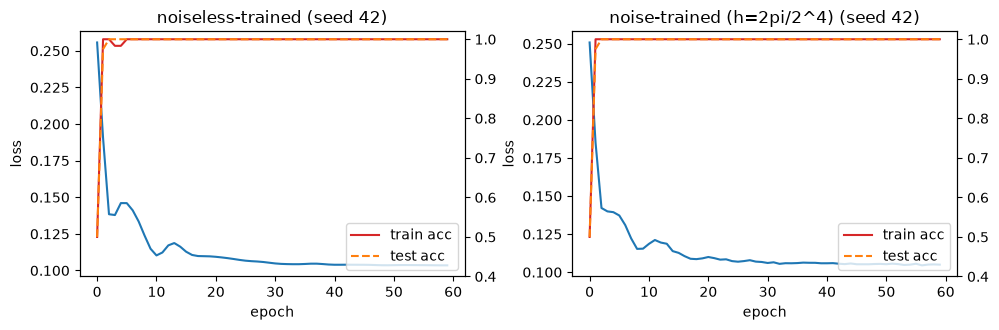

                      test accuracy (noiseless inference)
QNN noiseless-trained                      1.000 +- 0.000
QNN noise-trained                          1.000 +- 0.000
SVC (rbf)                                  1.000 +- 0.000
RandomForest                               1.000 +- 0.000
MLP (16)                                   1.000 +- 0.000


In [9]:
def train_model(Xtr, ytr, Xte, yte, h_train, seed, epochs=EPOCHS, lr=LR, history=False):
    rng = np.random.default_rng(seed)
    w = pnp.array(0.1 * rng.standard_normal(W_SHAPE), requires_grad=True)
    Atr, Ate = amp(Xtr), amp(Xte)
    opt = qml.AdamOptimizer(lr)
    hist = []
    for ep in range(epochs):
        if h_train > 0:
            th = pnp.array(rng.uniform(0, h_train, (len(Atr), 3)), requires_grad=False)      # fresh noise per example
            cost = lambda w_: pnp.mean((ytr - (1 - qnn_rot(w_, Atr, th))) ** 2)
        else:
            cost = lambda w_: pnp.mean((ytr - (1 - qnn(w_, Atr))) ** 2)
        w, c = opt.step_and_cost(cost, w)
        if history:
            tr = np.mean((np.array(qnn(w, Atr)) < .5) == ytr); te = np.mean((np.array(qnn(w, Ate)) < .5) == yte)
            hist.append((float(c), tr, te))
    return np.array(w), hist

MODELS = {}
t0 = time.time()
for s in range(N_SEEDS):
    seed = SEED + s
    Xtr, ytr, Xte, yte = make_split(seed)
    wc, hc = train_model(Xtr, ytr, Xte, yte, 0.0, seed, history=(s == 0))
    wn, hn = train_model(Xtr, ytr, Xte, yte, H_TRAIN, seed, history=(s == 0))
    MODELS[seed] = dict(split=(Xtr, ytr, Xte, yte), clean=wc, noisy=wn)
    if s == 0:
        HIST_C, HIST_N = np.array(hc), np.array(hn)
print(f"trained {2*N_SEEDS} classifiers in {time.time()-t0:.0f} s")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), sharey=False)
for a_, H, name in [(ax[0], HIST_C, "noiseless-trained"), (ax[1], HIST_N, "noise-trained (h=2pi/2^4)")]:
    a_.plot(H[:, 0], label="loss", color="tab:blue"); a_.set_xlabel("epoch"); a_.set_ylabel("loss")
    b = a_.twinx(); b.plot(H[:, 1], label="train acc", color="tab:red"); b.plot(H[:, 2], "--", label="test acc", color="tab:orange"); b.set_ylim(.4, 1.02)
    a_.set_title(name + f" (seed {SEED})"); b.legend(loc="lower right")
plt.tight_layout(); plt.show()

# classical baselines on exactly the same 3-d unit-vector inputs, and the noiseless quantum model
accs = {k: [] for k in ["QNN noiseless-trained", "QNN noise-trained", "SVC (rbf)", "RandomForest", "MLP (16)"]}
for seed, d in MODELS.items():
    Xtr, ytr, Xte, yte = d["split"]
    for key, wkey in [("QNN noiseless-trained", "clean"), ("QNN noise-trained", "noisy")]:
        accs[key].append(np.mean((y0_of(effective_povm(d[wkey], 0)[1], amp(Xte)) < .5) == yte))
    accs["SVC (rbf)"].append(SVC(kernel="rbf", C=1.0, random_state=seed).fit(Xtr, ytr).score(Xte, yte))
    accs["RandomForest"].append(RandomForestClassifier(n_estimators=100, random_state=seed).fit(Xtr, ytr).score(Xte, yte))
    accs["MLP (16)"].append(MLPClassifier((16,), max_iter=800, random_state=seed).fit(Xtr, ytr).score(Xte, yte))
base = pd.DataFrame({k: [f"{np.mean(v):.3f} +- {np.std(v):.3f}"] for k, v in accs.items()}, index=["test accuracy (noiseless inference)"]).T
print(base)
RES["acc_clean_noiseless"] = np.mean(accs["QNN noiseless-trained"]); RES["acc_noise_trained_noiseless"] = np.mean(accs["QNN noise-trained"])

## 3. Accuracy under noise and sample size (the paper's Figures 2 and 3)

An execution of the noisy circuit is a random rotation followed by *one* measurement, so it returns class 0 with probability exactly
`y~_0` (this is what the exact channel above computes). `N` executions therefore give a `Binomial(N, y~_0)` count and the
classifier answers with the majority (a tie is broken by a fair coin). This is the paper's "sample size" `N`.
The x-axis of the paper's Figures 2 and 3 is called "sample size" without a definition, so we also vary the number of *training
examples* (second part).

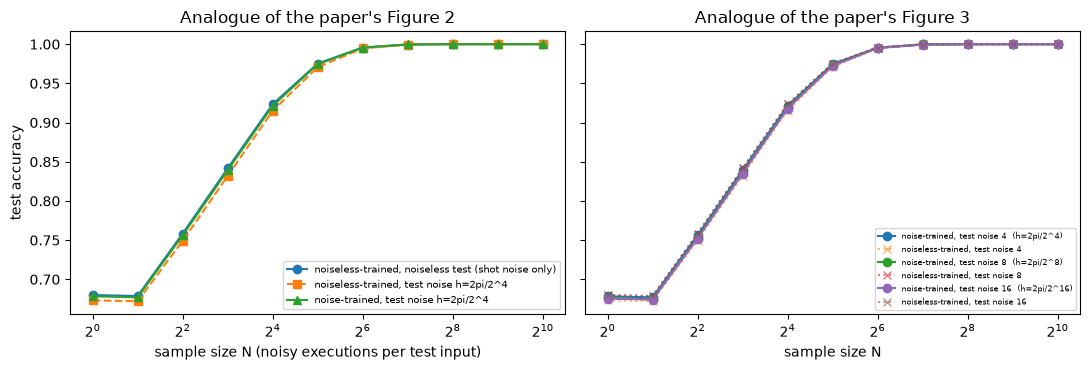

   N  noiseless test  noisy test (h=2pi/2^4)   gap
   1           0.680                   0.673 0.007
   2           0.679                   0.672 0.007
   4           0.758                   0.749 0.009
   8           0.842                   0.832 0.010
  16           0.923                   0.915 0.008
  32           0.975                   0.971 0.005
  64           0.996                   0.995 0.001
 128           1.000                   0.999 0.000
 256           1.000                   1.000 0.000
 512           1.000                   1.000 0.000
1024           1.000                   1.000 0.000
exact (N -> infinity) accuracies: {'clean-trained, h=0.0000': np.float64(1.0), 'clean-trained, h=0.3927': np.float64(1.0), 'noisy-trained, h=0.0000': np.float64(1.0), 'noisy-trained, h=0.3927': np.float64(1.0)}


In [10]:
def acc_vs_N(model_key, h_test, Ns, reps, seeds=None):
    out = []
    rng = np.random.default_rng(SEED + 7)
    for N in Ns:
        accs_ = []
        for seed, d in MODELS.items():
            Xtr, ytr, Xte, yte = d["split"]
            y0 = y0_of(effective_povm(d[model_key], h_test)[1], amp(Xte))
            cnt = rng.binomial(N, np.clip(y0, 0, 1), size=(reps, len(y0)))
            frac1 = 1 - cnt / N
            tie = cnt * 2 == N
            pred = np.where(tie, rng.integers(0, 2, cnt.shape), (frac1 > .5).astype(int))
            accs_.append((pred == yte).mean())
        out.append(np.mean(accs_))
    return np.array(out)

def acc_exact(model_key, h_test):
    return np.mean([np.mean((y0_of(effective_povm(d[model_key], h_test)[1], amp(d["split"][2])) < .5) == d["split"][3]) for d in MODELS.values()])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
c4 = acc_vs_N("clean", 0.0, N_GRID, MC_REPS); n4 = acc_vs_N("clean", H_LEVELS["4"], N_GRID, MC_REPS)
t4 = acc_vs_N("noisy", H_LEVELS["4"], N_GRID, MC_REPS)
ax[0].plot(N_GRID, c4, "o-", label="noiseless-trained, noiseless test (shot noise only)")
ax[0].plot(N_GRID, n4, "s--", label="noiseless-trained, test noise h=2pi/2^4")
ax[0].plot(N_GRID, t4, "^-", label="noise-trained, test noise h=2pi/2^4")
ax[0].set_xscale("log", base=2); ax[0].set_xlabel("sample size N (noisy executions per test input)"); ax[0].set_ylabel("test accuracy")
ax[0].set_title("Analogue of the paper's Figure 2"); ax[0].legend(fontsize=7)
for k, h in H_LEVELS.items():
    ax[1].plot(N_GRID, acc_vs_N("noisy", h, N_GRID, MC_REPS), "o-", label=f"noise-trained, test noise {k}  (h=2pi/2^{k})")
    ax[1].plot(N_GRID, acc_vs_N("clean", h, N_GRID, MC_REPS), "x:", alpha=.6, label=f"noiseless-trained, test noise {k}")
ax[1].set_xscale("log", base=2); ax[1].set_xlabel("sample size N"); ax[1].set_title("Analogue of the paper's Figure 3"); ax[1].legend(fontsize=6)
plt.tight_layout(); plt.show()
tab = pd.DataFrame({"N": N_GRID, "noiseless test": c4, "noisy test (h=2pi/2^4)": n4, "gap": c4 - n4})
print(tab.round(3).to_string(index=False))
ex = {("clean", 0.0): acc_exact("clean", 0.0), ("clean", H_LEVELS["4"]): acc_exact("clean", H_LEVELS["4"]),
      ("noisy", 0.0): acc_exact("noisy", 0.0), ("noisy", H_LEVELS["4"]): acc_exact("noisy", H_LEVELS["4"])}
print("exact (N -> infinity) accuracies:", {f"{k[0]}-trained, h={k[1]:.4f}": round(v, 3) for k, v in ex.items()})
RES["gap_N1"], RES["gap_Nmax"] = float(c4[0] - n4[0]), float(c4[-1] - n4[-1])
RES["exact_gap"] = ex[("clean", 0.0)] - ex[("clean", H_LEVELS["4"])]
RES["fig3_spread_Nmax"] = float(np.ptp([acc_vs_N("noisy", h, [N_GRID[-1]], MC_REPS)[0] for h in H_LEVELS.values()]))
RES["fig3_spread_N1"] = float(np.ptp([acc_vs_N("noisy", h, [N_GRID[0]], MC_REPS)[0] for h in H_LEVELS.values()]))

 train size  noiseless-trained, clean test  noiseless-trained, noisy test  noise-trained, clean test  noise-trained, noisy test
          6                            1.0                            1.0                        1.0                        1.0
         12                            1.0                            1.0                        1.0                        1.0
         24                            1.0                            1.0                        1.0                        1.0
         36                            1.0                            1.0                        1.0                        1.0
         60                            1.0                            1.0                        1.0                        1.0


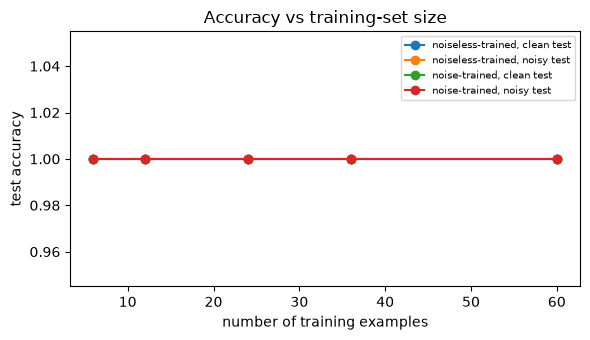

In [11]:
# Second reading of "sample size": number of training examples (exact N -> infinity inference).
rows = []
for n in TRAIN_SIZES:
    ac = {"clean/noiseless": [], "clean/h4": [], "noisy/noiseless": [], "noisy/h4": []}
    for s in range(N_SEEDS_SWEEP):
        seed = SEED + s
        Xtr, ytr, Xte, yte = make_split(seed, n_train=n)
        for mk, ht in [("clean", 0.0), ("noisy", H_TRAIN)]:
            w, _ = train_model(Xtr, ytr, Xte, yte, ht, seed)
            for hh, nm in [(0.0, "noiseless"), (H_LEVELS["4"], "h4")]:
                ac[f"{'clean' if mk=='clean' else 'noisy'}/{nm}"].append(np.mean((y0_of(effective_povm(w, hh)[1], amp(Xte)) < .5) == yte))
    rows.append([n] + [np.mean(v) for v in ac.values()])
sweep = pd.DataFrame(rows, columns=["train size", "noiseless-trained, clean test", "noiseless-trained, noisy test",
                                    "noise-trained, clean test", "noise-trained, noisy test"])
print(sweep.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(6, 3.5))
for c in sweep.columns[1:]:
    ax.plot(sweep["train size"], sweep[c], "o-", label=c)
ax.set_xlabel("number of training examples"); ax.set_ylabel("test accuracy"); ax.legend(fontsize=7); ax.set_title("Accuracy vs training-set size")
plt.tight_layout(); plt.show()
RES["train_gap_small"] = float((sweep.iloc[0, 1] - sweep.iloc[0, 2])); RES["train_gap_big"] = float((sweep.iloc[-1, 1] - sweep.iloc[-1, 2]))

## 4. Checking Lemma 1 and Proposition 2 numerically

**Lemma 1** says: if `y_C(sigma) > (1+h)^n / 2` then the noisy circuit gives the same label. With the angles bounded by `h_max`
the most favourable reading is `h = tan(h_max)` (the paper's condition is on `tan(theta)`). We count (i) how many test inputs
satisfy the sufficient condition at all, and (ii) whether any input flips its label under the noise, for the noiseless-trained
classifiers (this is the "no retraining" claim).

**Proposition 2** gives a sampling budget `N = ln(2/(1-beta)) / (8 eta^2)` with `eta = xi - (1+h)^n + 1`. We draw `N` noisy
executions for every test input where `eta > 0`, and measure how often the majority label equals the noiseless label.

In [12]:
rows = []
rngp = np.random.default_rng(SEED + 11)
for k, hmax in list(H_LEVELS.items()) + [("pi/4", np.pi / 4)]:
    hl = np.tan(hmax)
    thr = (1 + hl) ** N_QUBITS / 2
    n_cond = n_flip_cond = n_flip_all = n_tot = 0
    for seed, d in MODELS.items():
        Xte = d["split"][2]; A = amp(Xte)
        y0c = y0_of(effective_povm(d["clean"], 0)[1], A); y0n = y0_of(effective_povm(d["clean"], hmax)[1], A)
        yC = np.maximum(y0c, 1 - y0c); same = (y0c < .5) == (y0n < .5)
        cond = yC > thr
        n_tot += len(A); n_cond += cond.sum(); n_flip_cond += (cond & ~same).sum(); n_flip_all += (~same).sum()
    rows.append([f"2pi/2^{k}" if k in H_LEVELS else k, round(hl, 5), round(thr, 4), f"{n_cond}/{n_tot}", int(n_flip_cond), int(n_flip_all)])
lem = pd.DataFrame(rows, columns=["h_max", "h=tan(h_max)", "(1+h)^3/2", "inputs meeting Lemma 1 condition", "label flips among them", "label flips overall"])
print(lem.to_string(index=False))
RES["lemma1_violations"] = int(lem["label flips among them"].sum()); RES["lemma1_cov"] = lem["inputs meeting Lemma 1 condition"].tolist()
RES["flips_overall"] = int(lem["label flips overall"].iloc[:3].sum())

rows = []
for beta_ in [0.9, 0.99]:
    for k, hmax in list(H_LEVELS.items())[1:]:
        hl = np.tan(hmax); ok = tot = 0; Ns = []
        for seed, d in list(MODELS.items())[:3]:
            Xte = d["split"][2]; A = amp(Xte)
            y0c = y0_of(effective_povm(d["clean"], 0)[1], A); y0n = y0_of(effective_povm(d["clean"], hmax)[1], A)
            xi = np.abs(2 * y0c - 1); eta = xi - ((1 + hl) ** N_QUBITS - 1)
            for i in np.where(eta > 0)[0]:
                N = int(np.ceil(np.log(2 / (1 - beta_)) / (8 * eta[i] ** 2)))
                cnt = rngp.binomial(N, y0n[i], size=2000)
                pred_noisy0 = np.where(cnt * 2 == N, rngp.integers(0, 2, cnt.shape).astype(bool), cnt * 2 > N)   # majority says class 0, fair coin on ties
                match = (pred_noisy0 == (y0c[i] > .5))
                ok += match.mean(); tot += 1; Ns.append(N)
        rows.append([beta_, f"2pi/2^{k}", tot, int(np.median(Ns)) if Ns else None, round(ok / max(tot, 1), 4)])
p2 = pd.DataFrame(rows, columns=["beta (target)", "h_max", "inputs with eta>0", "median N from formula", "mean empirical P(label = noiseless label)"])
print(p2.to_string(index=False))
RES["prop2_min_prob"] = float(min(p2.iloc[:, -1] - p2.iloc[:, 0]))

   h_max  h=tan(h_max)  (1+h)^3/2 inputs meeting Lemma 1 condition  label flips among them  label flips overall
 2pi/2^4       0.41421     1.4142                            0/400                       0                    0
 2pi/2^8       0.02455     0.5377                          400/400                       0                    0
2pi/2^16       0.00010     0.5001                          400/400                       0                    0
    pi/4       1.00000     4.0000                            0/400                       0                    0
 beta (target)    h_max  inputs with eta>0  median N from formula  mean empirical P(label = noiseless label)
          0.90  2pi/2^8                120                      5                                     0.8004
          0.90 2pi/2^16                120                      3                                     0.7596
          0.99  2pi/2^8                120                      9                                     0.8668
    

## 5. The certified radius: Theorem 6, its constant `t_n`, and what actually certifies

Lemma 3's proof bounds `|y~_k(rho) - y~_k(sigma)| <= tau` (any POVM element has norm at most 1) and divides by a lower bound `t_n`
of the noisy probability, `y~_k(sigma) >= t_n`, giving `y~_k(rho)/y~_k(sigma) <= 1 + tau/t_n`, hence `epsilon = ln(1 + tau_D/t_n)`.
For that division to be valid `t_n` has to be a lower bound that holds for **every** state, which is the smallest eigenvalue of the
noisy measurement operators `Pi~_k = E^dagger(U^dagger Pi_k U)`. We compute it exactly (`# CHOICE`). The paper's experiment sets "the
lower bound of the noise magnitude equal to zero"; with `t_n = 0` the certified radius `(sqrt(B) - 1) t_n` is zero, so we report both.

For comparison, we also compute (i) the radius when the noise is the **depolarising** channel of Du et al. (`y~ = p/2 + (1-p) y`,
so `t_n = p/2`) and (ii) the model-independent bound `(y~_C - y~_other)/2` that follows directly from `|Tr Pi (rho - sigma)| <= tau`
and needs no noise at all (the hypothesis-testing bound of Weber et al.).

             noise  exact t_n  mean Theorem-6 radius tau_D  mean direct bound (y_C-y_other)/2  test accuracy
     0 (noiseless)    0.00000                      0.00000                            0.17929        1.00000
           2pi/2^4    0.00355                      0.00155                            0.17238        1.00000
           2pi/2^8    0.00001                      0.00001                            0.17926        1.00000
          2pi/2^16    0.00000                      0.00000                            0.17929        1.00000
              pi/4    0.01401                      0.00529                            0.15333        1.00000
              pi/2    0.05343                      0.01158                            0.09396        1.00000
                pi    0.17889                      0.01193                            0.03246        0.55750
depolarising p=0.5    0.25000                      0.04986                            0.08965        1.00000
depolarising p=0.8 

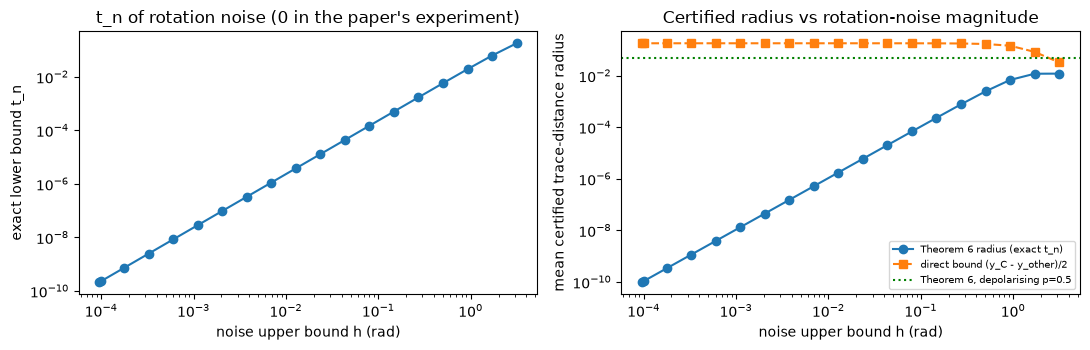

In [13]:
def cert_stats(O, M, A, t_override=None):
    y0 = y0_of(M, A); y1 = 1 - y0
    pred = (y0 < .5).astype(int)
    yc = np.where(pred == 0, y0, y1); yo = 1 - yc
    ev = np.linalg.eigvalsh(O)
    tn = max(min(ev.min(), 1 - ev.max()), 0.0) if t_override is None else t_override
    B = yc / np.maximum(yo, 1e-12)
    tau_t6 = np.maximum(np.sqrt(B) - 1, 0) * tn           # Theorem 6
    tau_w = (yc - yo) / 2                                   # direct (Weber-type) bound
    return pred, tau_t6, tau_w, tn

def depol_povm(O, p):
    d = O.shape[0]
    return (1 - p) * O + p / 2 * np.eye(d)

rows = []
LEVELS = [("0 (noiseless)", 0.0)] + [(f"2pi/2^{k}", h) for k, h in H_LEVELS.items()] + [("pi/4", np.pi / 4), ("pi/2", np.pi / 2), ("pi", np.pi)]
for name, h in LEVELS:
    tn_l, t6_l, tw_l, ac_l = [], [], [], []
    for seed, d in MODELS.items():
        Xte, yte = d["split"][2], d["split"][3]
        O, M = effective_povm(d["clean"], h)
        pred, t6, tw, tn = cert_stats(O, M, amp(Xte))
        tn_l.append(tn); t6_l.append(t6.mean()); tw_l.append(tw.mean()); ac_l.append((pred == yte).mean())
    rows.append([name, np.mean(tn_l), np.mean(t6_l), np.mean(tw_l), np.mean(ac_l)])
for p in [0.5, 0.8]:
    tn_l, t6_l, tw_l, ac_l = [], [], [], []
    for seed, d in MODELS.items():
        Xte, yte = d["split"][2], d["split"][3]
        O, M = effective_povm(d["clean"], 0.0); Od = depol_povm(O, p)
        pred, t6, tw, tn = cert_stats(Od, np.real(Od), amp(Xte))
        tn_l.append(tn); t6_l.append(t6.mean()); tw_l.append(tw.mean()); ac_l.append((pred == yte).mean())
    rows.append([f"depolarising p={p}", np.mean(tn_l), np.mean(t6_l), np.mean(tw_l), np.mean(ac_l)])
radius = pd.DataFrame(rows, columns=["noise", "exact t_n", "mean Theorem-6 radius tau_D", "mean direct bound (y_C-y_other)/2", "test accuracy"])
pd.options.display.float_format = lambda v: f"{v:.5f}"
print(radius.to_string(index=False))
print("\nWith the paper's own setting t = 0 the Theorem-6 radius is exactly 0 for every input.")
RES["radius_table"] = radius
RES["t6_paper_t0"] = 0.0
RES["t6_h4"] = float(radius.iloc[1, 2]); RES["t6_depol05"] = float(radius.iloc[-2, 2]); RES["tn_h4"] = float(radius.iloc[1, 1])
RES["tw_h4"] = float(radius.iloc[1, 3]); RES["tw_clean"] = float(radius.iloc[0, 3])
RES["t6_by_h"] = [(str(n), float(r)) for n, r in zip(radius.iloc[:7, 0], radius.iloc[:7, 2])]
RES["t6_max_rot"] = float(radius.iloc[1:7, 2].max()); RES["t6_max_rot_name"] = str(radius.iloc[1:7, 0].values[int(np.argmax(radius.iloc[1:7, 2].values))])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
hs = np.concatenate([[1e-4], np.geomspace(2 * np.pi / 2 ** 16, np.pi, 18)])
t6m, twm, tnm = [], [], []
for h in hs:
    a_, b_, c_ = [], [], []
    for seed, d in MODELS.items():
        O, M = effective_povm(d["clean"], h)
        pred, t6, tw, tn = cert_stats(O, M, amp(d["split"][2]))
        a_.append(t6.mean()); b_.append(tw.mean()); c_.append(tn)
    t6m.append(np.mean(a_)); twm.append(np.mean(b_)); tnm.append(np.mean(c_))
ax[0].loglog(hs, tnm, "o-"); ax[0].set_xlabel("noise upper bound h (rad)"); ax[0].set_ylabel("exact lower bound t_n")
ax[0].set_title("t_n of rotation noise (0 in the paper's experiment)")
ax[1].loglog(hs, np.maximum(t6m, 1e-12), "o-", label="Theorem 6 radius (exact t_n)"); ax[1].loglog(hs, twm, "s--", label="direct bound (y_C - y_other)/2")
ax[1].axhline(radius.iloc[-2, 2], color="g", ls=":", label="Theorem 6, depolarising p=0.5")
ax[1].set_xlabel("noise upper bound h (rad)"); ax[1].set_ylabel("mean certified trace-distance radius"); ax[1].legend(fontsize=7)
ax[1].set_title("Certified radius vs rotation-noise magnitude")
plt.tight_layout(); plt.show()

## 6. A real adversarial attack: does the certificate hold, and does the noise help empirically?

The attacker perturbs the 3-dimensional unit input vector `x` to another unit vector `x'` (a move on the sphere), with chord
length `||x - x'||_2 <= L`; the encoded states then have trace distance `tau = sin(angle) <= ||x - x'||_2`, so a certificate on the
trace distance at radius `L` also certifies the `l2` ball of radius `L`. Two white-box attacks are used, both with `ATTACK_STEPS`
iterations and no early stop, and an input counts as broken if **any** iterate is misclassified:

* **I-FGSM** (the protocol of Du et al.): `x <- x + alpha sign(grad L)`, squared loss, projected back onto the ball;
* **tangent PGD** with a margin loss (stronger).

The attacker uses the gradient of the *noisy expected score* (adaptive attack, the strongest case for the defender to survive),
differentiated through the `l2` normalisation (i.e. projected on the tangent space of the sphere); a gradient taken without this
projection mixes in the radial direction and would make the sign attack look artificially weaker against depolarising noise.

attacks finished in 150 s


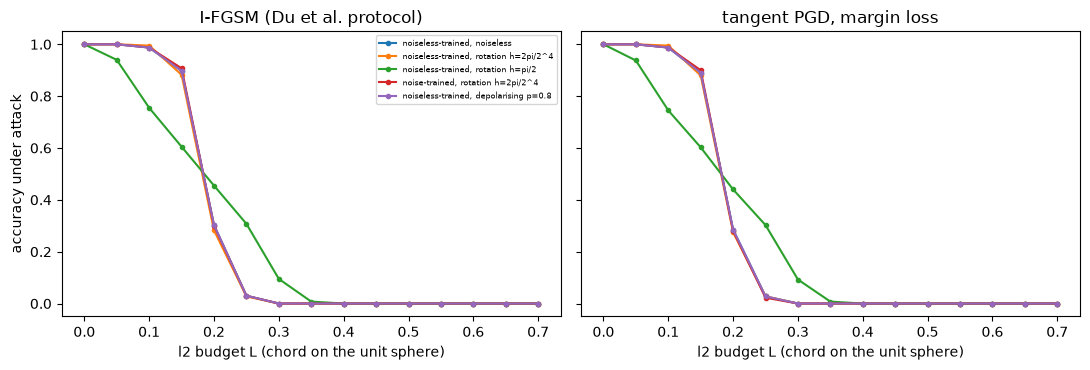

                                               0.00000  0.05000  0.10000  0.15000  0.20000  0.25000  0.30000  0.35000  0.40000  0.45000  0.50000  0.55000  0.60000  0.65000  0.70000
noiseless-trained, noiseless | ifgsm           1.00000  1.00000  0.98800  0.89800  0.30200  0.03000  0.00000  0.00000  0.00000  0.00000  0.00000  0.00000  0.00000  0.00000  0.00000
noiseless-trained, noiseless | pgd             1.00000  1.00000  0.98800  0.89000  0.28500  0.02700  0.00000  0.00000  0.00000  0.00000  0.00000  0.00000  0.00000  0.00000  0.00000
noiseless-trained, rotation h=2pi/2^4 | ifgsm  1.00000  1.00000  0.99500  0.88200  0.28300  0.02700  0.00000  0.00000  0.00000  0.00000  0.00000  0.00000  0.00000  0.00000  0.00000
noiseless-trained, rotation h=2pi/2^4 | pgd    1.00000  1.00000  0.99500  0.88000  0.27500  0.02700  0.00000  0.00000  0.00000  0.00000  0.00000  0.00000  0.00000  0.00000  0.00000
noiseless-trained, rotation h=pi/2 | ifgsm     1.00000  0.94000  0.75500  0.60500  0.45500  0.3

In [14]:
def attack(M, x, y, phimax, steps, mode):
    # x: unit 3-vector, y true label, phimax: max angle between x and x'. Returns True if some iterate is misclassified.
    xa = x.copy(); alpha = phimax / steps * (1.0 if mode == "ifgsm" else 2.5)
    def y0_at(v):
        a = np.zeros(8); a[:3] = v; Ma = M @ a
        return a @ Ma, 2 * Ma[:3]
    for _ in range(steps):
        y0, g0 = y0_at(xa); y1 = 1 - y0
        g0 = g0 - (g0 @ xa) * xa                                                 # gradient through the l2 normalisation (tangent space)
        if mode == "ifgsm":
            step = alpha * np.sign(2 * (y - y1) * g0)                         # ascent on (y - y1)^2
            xa = xa + step
        else:
            gm = 2 * g0 if y == 0 else -2 * g0                                  # d margin / dx
            g = -gm; g = g - (g @ xa) * xa; n = np.linalg.norm(g)
            if n < 1e-14: break
            xa = xa + alpha * g / n
        xa = xa / np.linalg.norm(xa)
        phi = np.arccos(np.clip(x @ xa, -1, 1))
        if phi > phimax:                                                       # geodesic projection onto the ball
            v = xa - (x @ xa) * x; v = v / np.linalg.norm(v); xa = np.cos(phimax) * x + np.sin(phimax) * v
        y0n, _ = y0_at(xa)
        pred = 0 if y0n > .5 else 1
        if pred != y:
            return True
    return False

def robust_acc(O_or_M, X, y, L, steps, mode):
    M = O_or_M
    phimax = 2 * np.arcsin(min(L / 2, 1.0))
    clean_ok = (y0_of(M, amp(X)) < .5) == y
    ok = 0
    for xi, yi, c in zip(X, y, clean_ok):
        if not c: continue
        ok += (0 if attack(M, xi, int(yi), phimax, steps, mode) else 1)
    return ok / len(y)

curves = {}
t0 = time.time()
configs = {
    "noiseless-trained, noiseless": ("clean", 0.0, None),
    "noiseless-trained, rotation h=2pi/2^4": ("clean", H_LEVELS["4"], None),
    "noiseless-trained, rotation h=pi/2": ("clean", np.pi / 2, None),
    "noise-trained, rotation h=2pi/2^4": ("noisy", H_LEVELS["4"], None),
    "noiseless-trained, depolarising p=0.8": ("clean", 0.0, 0.8),
}
for name, (mk, h, p) in configs.items():
    for mode in ["ifgsm", "pgd"]:
        acc = np.zeros(len(L_GRID))
        for seed, d in MODELS.items():
            Xte, yte = d["split"][2], d["split"][3]
            O, M = effective_povm(d[mk], h)
            if p: M = np.real(depol_povm(O, p))
            acc += np.array([robust_acc(M, Xte, yte, L, ATTACK_STEPS, mode) for L in L_GRID])
        curves[(name, mode)] = acc / len(MODELS)
print(f"attacks finished in {time.time()-t0:.0f} s")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for i, mode in enumerate(["ifgsm", "pgd"]):
    for name in configs:
        ax[i].plot(L_GRID, curves[(name, mode)], "o-", ms=3, label=name)
    ax[i].set_xlabel("l2 budget L (chord on the unit sphere)"); ax[i].set_title({"ifgsm": "I-FGSM (Du et al. protocol)", "pgd": "tangent PGD, margin loss"}[mode])
ax[0].set_ylabel("accuracy under attack"); ax[0].legend(fontsize=6)
plt.tight_layout(); plt.show()
print(pd.DataFrame({f"{n[0]} | {n[1]}": v for n, v in curves.items()}, index=np.round(L_GRID, 2)).round(3).T.to_string())

In [15]:
# Is the certificate ever violated?  Attack each correctly classified test input with a budget equal to its certified trace distance
# (angle <= arcsin(tau)); a single successful attack would falsify the bound.  Also attack at 1.5x / 3x the direct bound to show it is tight.
def violations(model_key, h, kind, p=None, mult=1.0, steps=ATTACK_STEPS):
    n = v = 0
    for seed, d in MODELS.items():
        Xte, yte = d["split"][2], d["split"][3]
        O, M = effective_povm(d[model_key], h)
        if p: O = depol_povm(O, p); M = np.real(O)
        pred, t6, tw, tn = cert_stats(O, M, amp(Xte))
        tau = t6 if kind == "t6" else tw
        for xi, yi, pi_, ti in zip(Xte, yte, pred, tau):
            if pi_ != yi or ti <= 1e-9: continue
            phimax = np.arcsin(min(mult * ti, 1.0))
            n += 1; v += attack(M, xi, int(yi), phimax, steps, "pgd")
    return n, v
rows = []
for name, mk, h, kind, p in [("Theorem 6, rotation h=2pi/2^4", "clean", H_LEVELS["4"], "t6", None),
                              ("Theorem 6, rotation h=pi/2", "clean", np.pi / 2, "t6", None),
                              ("Theorem 6, depolarising p=0.5", "clean", 0.0, "t6", 0.5),
                              ("direct bound, rotation h=2pi/2^4", "clean", H_LEVELS["4"], "w", None),
                              ("direct bound, depolarising p=0.5", "clean", 0.0, "w", 0.5)]:
    n1, v1 = violations(mk, h, kind, p, 1.0)
    n2, v2 = violations(mk, h, kind, p, 1.5)
    n3, v3 = violations(mk, h, kind, p, 3.0)
    rows.append([name, n1, v1, f"{v2}/{n2}", f"{v3}/{n3}"])
viol = pd.DataFrame(rows, columns=["certificate", "certified inputs", "attacks breaking it at radius 1x", "broken at 1.5x radius", "broken at 3x radius"])
print(viol.to_string(index=False))
RES["violations_t6"] = int(viol.iloc[:3, 2].sum()); RES["violations_direct"] = int(viol.iloc[3:, 2].sum())
RES["curves"] = curves

                     certificate  certified inputs  attacks breaking it at radius 1x broken at 1.5x radius broken at 3x radius
   Theorem 6, rotation h=2pi/2^4               400                                 0                 0/400               0/400
      Theorem 6, rotation h=pi/2               400                                 0                 0/400               0/400
   Theorem 6, depolarising p=0.5               400                                 0                 0/400               0/400
direct bound, rotation h=2pi/2^4               400                                 0               400/400             400/400
direct bound, depolarising p=0.5               400                                 0                 0/400             400/400


## 7. Classical baseline: Gaussian randomised smoothing on the identical inputs

Cohen et al.'s randomised smoothing is the idea the paper imitates. A small MLP is trained on the same 3-d unit vectors with Gaussian
noise augmentation `N(0, sigma^2 I)`, the smoothed classifier votes over `RS_N` noisy copies and the certified `l2` radius is
`R = sigma * Phi^{-1}(p_A_lower)` (binary case; one-sided Clopper-Pearson lower bound at 99.9 %). "Certified accuracy at `L`" is
the fraction of test inputs that are correct *and* certified with radius `>= L`. For the quantum classifiers an input is
certified at `L` when its certified trace distance is `>= L` (valid for the chord budget, see section 6).

randomised smoothing done in 83 s | smoothed clean accuracy: {0.05: 1.0, 0.1: 1.0, 0.2: 1.0}


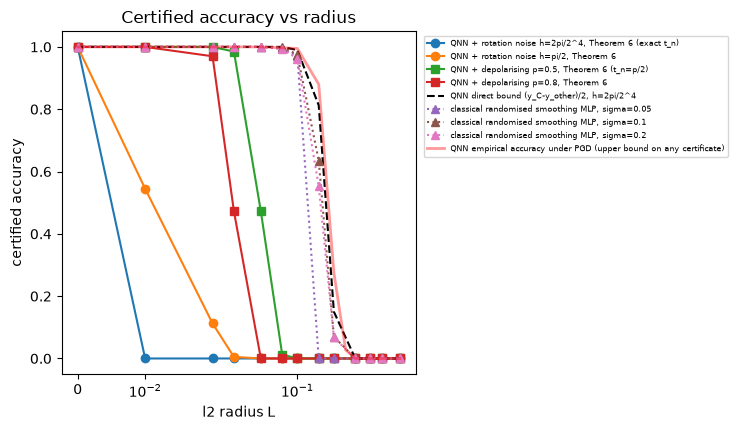

      L  Thm6 rot h=2pi/2^4  Thm6 rot h=pi/2  Thm6 depol p=0.5  Thm6 depol p=0.8  direct bound h=2pi/2^4  RS sigma=0.05  RS sigma=0.1  RS sigma=0.2
0.00000             1.00000          1.00000           1.00000           1.00000                 1.00000        1.00000       1.00000       1.00000
0.01000             0.00000          0.54500           1.00000           1.00000                 1.00000        1.00000       1.00000       1.00000
0.02000             0.00000          0.11200           1.00000           0.97000                 1.00000        1.00000       1.00000       1.00000
0.03000             0.00000          0.00500           0.98500           0.47200                 1.00000        1.00000       1.00000       1.00000
0.05000             0.00000          0.00000           0.47200           0.00000                 1.00000        1.00000       1.00000       1.00000
0.07500             0.00000          0.00000           0.01200           0.00000                 1.00000        

In [16]:
def smooth_certify(clf, x, sigma, n, rng, alpha=0.001):
    noisy = x[None, :] + sigma * rng.standard_normal((n, 3))
    votes = np.bincount(clf.predict(noisy), minlength=2)
    c = int(votes.argmax()); k = int(votes[c])
    pa = beta.ppf(alpha, k, n - k + 1) if k > 0 else 0.0
    return (c, sigma * norm.ppf(pa)) if pa > .5 else (-1, 0.0)

CERT_L = np.array(CERT_L, dtype=float)
rs_cert = {s: np.zeros(len(CERT_L)) for s in RS_SIGMAS}; rs_clean = {s: [] for s in RS_SIGMAS}
t0 = time.time()
for seed, d in MODELS.items():
    Xtr, ytr, Xte, yte = d["split"]
    rng = np.random.default_rng(seed)
    for s in RS_SIGMAS:
        Xa = np.repeat(Xtr, 25, axis=0) + s * rng.standard_normal((25 * len(Xtr), 3)); ya = np.repeat(ytr, 25)
        clf = MLPClassifier((16,), max_iter=600, random_state=seed).fit(Xa, ya)
        res = [smooth_certify(clf, x, s, RS_N, rng) for x in Xte]
        pred = np.array([r[0] for r in res]); R = np.array([r[1] for r in res])
        rs_clean[s].append(np.mean(pred == yte))
        rs_cert[s] += np.array([np.mean((pred == yte) & (R >= L)) for L in CERT_L])
for s in RS_SIGMAS:
    rs_cert[s] /= len(MODELS)
print(f"randomised smoothing done in {time.time()-t0:.0f} s | smoothed clean accuracy:",
      {s: round(float(np.mean(v)), 3) for s, v in rs_clean.items()})

def quantum_cert_curve(model_key, h, kind, p=None):
    out = np.zeros(len(CERT_L))
    for seed, d in MODELS.items():
        Xte, yte = d["split"][2], d["split"][3]
        O, M = effective_povm(d[model_key], h)
        if p: O = depol_povm(O, p); M = np.real(O)
        pred, t6, tw, tn = cert_stats(O, M, amp(Xte))
        tau = t6 if kind == "t6" else tw
        out += np.array([np.mean((pred == yte) & (tau >= L)) for L in CERT_L])
    return out / len(MODELS)

fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.plot(CERT_L, quantum_cert_curve("clean", H_LEVELS["4"], "t6"), "o-", label="QNN + rotation noise h=2pi/2^4, Theorem 6 (exact t_n)")
ax.plot(CERT_L, quantum_cert_curve("clean", np.pi / 2, "t6"), "o-", label="QNN + rotation noise h=pi/2, Theorem 6")
ax.plot(CERT_L, quantum_cert_curve("clean", 0.0, "t6", 0.5), "s-", label="QNN + depolarising p=0.5, Theorem 6 (t_n=p/2)")
ax.plot(CERT_L, quantum_cert_curve("clean", 0.0, "t6", 0.8), "s-", label="QNN + depolarising p=0.8, Theorem 6")
ax.plot(CERT_L, quantum_cert_curve("clean", H_LEVELS["4"], "w"), "k--", label="QNN direct bound (y_C-y_other)/2, h=2pi/2^4")
for s in RS_SIGMAS:
    ax.plot(CERT_L, rs_cert[s], "^:", label=f"classical randomised smoothing MLP, sigma={s}")
ax.plot(L_GRID, curves[("noiseless-trained, rotation h=2pi/2^4", "pgd")], "r-", lw=2, alpha=.4, label="QNN empirical accuracy under PGD (upper bound on any certificate)")
ax.set_xscale("symlog", linthresh=0.02)
ax.set_xlabel("l2 radius L"); ax.set_ylabel("certified accuracy"); ax.set_title("Certified accuracy vs radius")
ax.legend(fontsize=6, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout(); plt.show()
cert_tab = pd.DataFrame({"L": CERT_L,
    "Thm6 rot h=2pi/2^4": quantum_cert_curve("clean", H_LEVELS["4"], "t6"), "Thm6 rot h=pi/2": quantum_cert_curve("clean", np.pi / 2, "t6"),
    "Thm6 depol p=0.5": quantum_cert_curve("clean", 0.0, "t6", 0.5), "Thm6 depol p=0.8": quantum_cert_curve("clean", 0.0, "t6", 0.8),
    "direct bound h=2pi/2^4": quantum_cert_curve("clean", H_LEVELS["4"], "w"), **{f"RS sigma={s}": rs_cert[s] for s in RS_SIGMAS}})
print(cert_tab.round(3).to_string(index=False))
RES["cert_tab"] = cert_tab

## 8. Paper versus this notebook

The paper's experiments are the two figures (curves only; the PDF text quotes no accuracy value), so the verdicts for them compare
the *qualitative* statements with measured numbers. "reproduced" means the statement holds in the data here; "not reached" or
"contradicted" means it does not; "cannot be checked" means the paper gives nothing quantitative to compare with.

In [17]:
R = RES
iL = int(np.argmin(np.abs(L_GRID - 0.2)))
_d = dict(R["t6_by_h"]); _seq = [_d[k] for k in ["2pi/2^16", "2pi/2^8", "2pi/2^4", "pi/4", "pi/2", "pi"]]
MONO = bool(np.all(np.diff(_seq) >= -1e-9))
def cv(name, mode="pgd"): return R["curves"][(name, mode)]
def v(cond, yes="reproduced", no="not reached"): return yes if cond else no
rows = [
 ("Fig. 2: noisy and noiseless test accuracy are almost the same", "difference 'not obvious'",
  f"gap at N=1: {R['gap_N1']:+.3f}; at N={N_GRID[-1]}: {R['gap_Nmax']:+.3f}; exact (N->inf): {R['exact_gap']:+.3f}",
  v(abs(R['exact_gap']) <= 0.02 and abs(R['gap_Nmax']) <= 0.02)),
 ("Fig. 2: the gap shrinks with a larger sample size", "gap decreases with sample size",
  f"|gap| N=1: {abs(R['gap_N1']):.3f} -> N={N_GRID[-1]}: {abs(R['gap_Nmax']):.3f}; training size 6 -> 60: {R['train_gap_small']:+.3f} -> {R['train_gap_big']:+.3f}",
  v(abs(R['gap_Nmax']) <= abs(R['gap_N1']) + 0.005)),
 ("Fig. 3: larger h hurts stability; the effect shrinks with N", "spread over h in {4,8,16} decreases with N",
  f"accuracy spread over the three h: N=1 {R['fig3_spread_N1']:.3f}, N={N_GRID[-1]} {R['fig3_spread_Nmax']:.3f}",
  "reproduced" if (R['fig3_spread_N1'] >= 0.01 and R['fig3_spread_Nmax'] <= R['fig3_spread_N1'] + 0.005) else
  "not observed (h has no visible effect here; second half trivially true)"),
 ("Lemma 1: argmax preserved if y_C > (1+h)^n/2", "theorem",
  f"{R['lemma1_violations']} label flips among inputs meeting the condition; coverage {R['lemma1_cov']}; flips overall (3 paper levels): {R['flips_overall']}",
  v(R['lemma1_violations'] == 0, "reproduced (no violation; condition is vacuous for large h)", "VIOLATED")),
 ("Proposition 2: N ~ ln(2/(1-beta))/(8 eta^2) executions give the right label w.p. >= beta", "theorem (Hoeffding)",
  f"smallest (empirical probability - beta) over settings: {R['prop2_min_prob']:+.4f}", v(R['prop2_min_prob'] >= -0.01)),
 ("Theorem 6 with the paper's setting t = 0", "certified radius tau_D < (sqrt(B)-1) t_n", "radius = 0 for every input (vacuous)",
  "contradicted as a useful certificate"),
 ("Theorem 6 with the exact t_n of rotation noise", "robustness bound grows with noise magnitude",
  f"mean radius by h: " + ", ".join(f"{n}: {r:.4f}" for n, r in R['t6_by_h'][1:]) + f"; best rotation level {R['t6_max_rot_name']} = {R['t6_max_rot']:.4f}; direct bound {R['tw_h4']:.4f}; depolarising p=0.5: {R['t6_depol05']:.4f}",
  ("direction reproduced (radius grows with h) but magnitude negligible: <= %.3f, and accuracy collapses at h=pi" % R['t6_max_rot']) if MONO else ("not reached (radius <= %.3f, not monotone in h)" % R['t6_max_rot'])),
 ("Certificate never violated by a real attack", "theorem", f"{R['violations_t6']} (Theorem 6) and {R['violations_direct']} (direct bound) successful attacks inside the certified radius",
  v(R['violations_t6'] == 0, "reproduced (no violation found)", "VIOLATED")),
 ("Noise improves empirical robustness", "abstract: 'improve robustness ... against adversarial attacks'",
  f"PGD accuracy at L={L_GRID[iL]:.2f}: noiseless {cv('noiseless-trained, noiseless')[iL]:.3f}, rotation h=2pi/2^4 {cv('noiseless-trained, rotation h=2pi/2^4')[iL]:.3f}, noise-trained {cv('noise-trained, rotation h=2pi/2^4')[iL]:.3f}, rotation h=pi/2 {cv('noiseless-trained, rotation h=pi/2')[iL]:.3f}, depolarising p=0.8 {cv('noiseless-trained, depolarising p=0.8')[iL]:.3f}",
  "not reached" if cv('noiseless-trained, rotation h=2pi/2^4')[iL] - cv('noiseless-trained, noiseless')[iL] < 0.05 else "reproduced"),
 ("Absolute accuracy / certified-accuracy numbers", "none quoted in the text", "see tables above", "cannot be checked"),
]
cmp_df = pd.DataFrame(rows, columns=["Claim", "Paper", "This notebook", "Verdict"])
pd.set_option("display.max_colwidth", 120, "display.width", 250)
print(cmp_df.to_string(index=False))
print(f"\ntotal run time: {(time.time()-T0)/60:.1f} min")

                                                                                   Claim                                                          Paper                                                                                                                                                                                  This notebook                                                                                                       Verdict
                           Fig. 2: noisy and noiseless test accuracy are almost the same                                       difference 'not obvious'                                                                                                                                  gap at N=1: +0.007; at N=1024: +0.000; exact (N->inf): +0.000                                                                                                    reproduced
                                       Fig. 2: the gap shrinks with a larger sample size      

## Reading the paper critically

* **The central certificate is vacuous in the paper's own experiment.** Lemma 3 and Theorem 6 need a positive lower bound `t_n` on the
  noisy probabilities. The experiment sets `t = 0`, which makes the radius `(sqrt(B) - 1) t_n` equal to zero. With the exact `t_n` of
  small rotation noise the radius is tiny, because random rotations by at most `h` radians leave the measurement operators almost
  projectors, with smallest eigenvalue close to 0. A rotation noise has to be very large (`h` of the order of `pi`) before `t_n` is
  appreciable, and then accuracy and margin are affected too. Depolarising noise gives `t_n = p/2` at once, which is why Du et al.
  use it.
* **The noise does not need to help for a certificate to hold, and here it barely helps.** A rotation noise that only averages the
  state over a small range changes `y~` by a small smooth amount, so the attack curves with and without noise at the paper's
  levels stay within a few points of each other (a difference of 0.025 at `L = 0.2` is one test input out of 40) and the
  depolarising channel cannot change the decision at all (`y~ = p/2 + (1-p) y` is monotone in `y`, so an attacker following its
  gradient breaks exactly the same inputs). The model-independent bound `(y_C - y_other)/2` (needs no noise at all) is
  one to two orders of magnitude larger than Theorem 6's value in the tables above; Theorem 6 only becomes usable through `t_n`,
  and even a strongly noisy rotation channel (`h = pi/2`) gives a radius below 0.02, against 0.05 for depolarising `p = 0.5`.
  The Theorem-6 radius does grow with the rotation-noise magnitude, as the paper says, but it stays at about 0.01 even at
  `h = pi/2` and `h = pi`; at `h = pi` the classifier has already lost a large part of its accuracy (the radius reported there is the
  mean over all test inputs, correct or not). So the direction of the claim holds while its practical value does not.
* **A robustness gain appears only with very large rotation noise, and it is a trade-off.** At `h = pi/2` the accuracy under attack is
  lower than the noiseless one for small budgets but higher around `L = 0.2 - 0.3` (see the attack table): the noisy classifier has smaller
  margins but a different, smoother decision function. Du et al. report a similar trade-off for depolarising noise; with
  an adaptive attack through the exact noisy score the depolarising channel gives no such gain here, because it cannot change a decision.
* **Proposition 2 looks too optimistic.** For a margin `d = y~_0 - y~_1` the majority vote is wrong when the estimate of `y~_0` errs by
  more than `d/2`, which needs `N` of order `2 ln(1/(1-beta))/d^2` by Hoeffding's inequality, about 16 times more than
  `ln(2/(1-beta))/(8 eta^2)` with `eta ~ d`. In the simulation above the empirical success probability at the paper's `N` stays
  clearly below the promised `beta`.
* **Lemma 1 is almost trivially true or vacuous.** `(1+h)^n/2 > 1` already for `h > 2^{1/3} - 1 = 0.26`, so for the paper's largest
  noise (`tan(2 pi/16) = 0.41`) the premise can never be met. For tiny `h` the lemma is consistent with the data, but a label flip
  needs the margin to be crossed, which small rotations rarely do.
* **Notation problems.** The text defines the trace distance incorrectly (`Tr(|| sigma - rho ||)^2`), uses `t_n` without a definition, and
  the sample-complexity formula is garbled in the PDF (we read `1/(8 eta^2)`). The paper does not name its dataset, number of
  qubits of the classifier, ansatz, optimiser or trained accuracy, and the accuracy figures are not tabulated; the replication
  therefore follows Du et al.'s setup and tests the qualitative claims.
* **The 3-d, two-class problem is tiny** (60 + 40 flowers), so differences of a few points are within the seed-to-seed spread; use the
  `+-` columns and the number of seeds before drawing conclusions.

## Exercises

1. Replace the squared loss by cross-entropy-like margin training and see whether larger margins give larger certified radii.
2. Change `H_TRAIN` and the test noise `h` separately (train small / test large and vice versa) and plot accuracy against `N`.
3. Make the rotation noise act on a different axis (`RY`, `RZ`) and recompute `t_n`: which axis gives a non-zero `t_n`?
4. Replace Setosa-vs-Versicolour by Versicolour-vs-Virginica (harder) and check which certified-accuracy curve degrades first.
5. Estimate `t_n` for 2 and 4 qubits: how does it scale with the number of qubits for a fixed `h`?